In [ ]:
import matplotlib.pyplot as pl
import numpy as np

def imshow(data, title=None, rotate=False, save=''):
    if rotate:
        origin = 'lower'
        orientation = 'vertical'
        aspect = 'equal'
    else:
        origin = 'upper'
        orientation = 'horizontal'
        aspect = 5
    pl.figure()
    pl.title(title)
    pl.imshow(data.T, origin=origin, aspect=aspect, interpolation='none')
    pl.colorbar(orientation=orientation)
    if save:
        pl.savefig('plots/' + save + '.png')

%matplotlib widget
#%config InlineBackend.figure_format = 'retina'

def min_max_3d(data):
    low = np.unravel_index(np.argmin(data), data.shape)
    high = np.unravel_index(np.argmax(data), data.shape)
    return data[low], data[high], low, high

eko: (100, 111, 6)
tor: (0, 0, 14)
wi: (0, 0, 0)


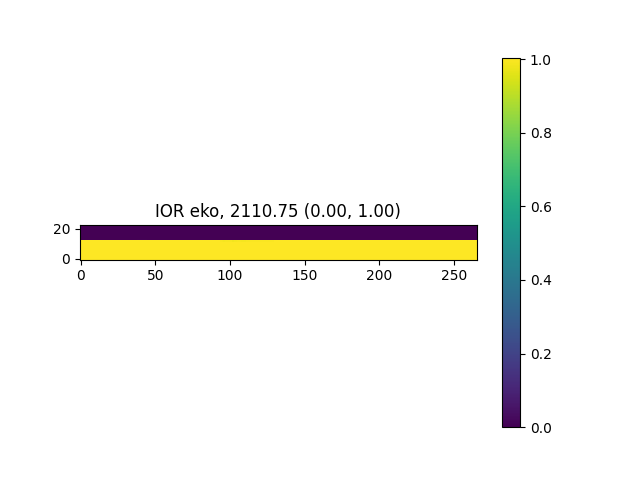

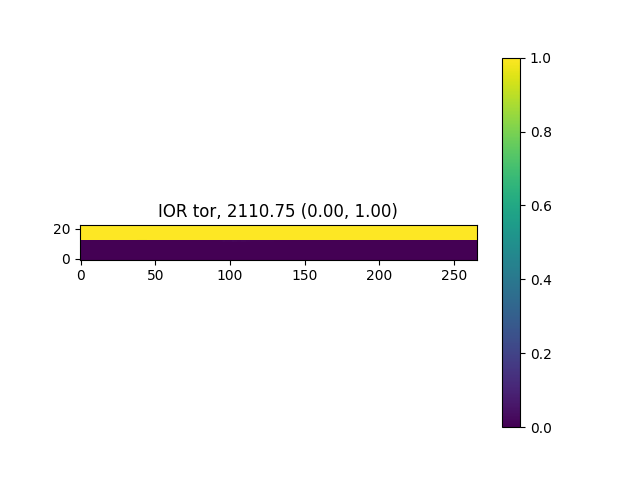

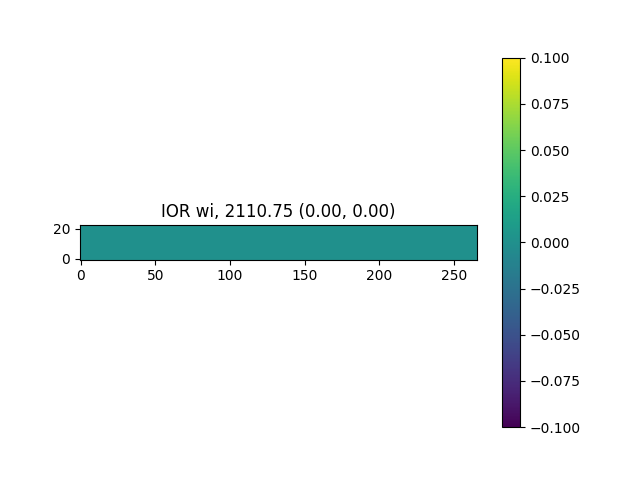

In [22]:
from pathlib import Path
from ior2ecl import Output

pl.close('all')

cop = Path.home() / 'CoP_files'
root = cop/'input/Model_From_IXF/Model_From_IXF'
root = cop/'input/IORSIM_BASECASE_SURF_RES/IORSIM_BASECASE_INPUT'

out = Output(root)
unrst = out.ior_unrst
end = list(unrst.steps())[-1]
 
#cut = (slice(100,None), slice(0, 100), 3)
#cut = (slice(None), slice(None), 6)
cut = (40, slice(None), slice(None))
rotate = True

start, stop, step = end, None, 1

keys = ('DOUBHEAD', 0, 'BA', 'BR', 'CA')
#keys = ('DOUBHEAD', 0, 'EKO', 'TOR', 'WI')
time, *data = next(unrst.blockdata(*keys, start=start, stop=stop, step=step))
eko, tor, wi = unrst.reshape_dim(*data)
l, h, argl, argh = min_max_3d(eko)
print('eko:', argh)
imshow(eko[cut], f'IOR eko, {time:.2f} ({l:.2f}, {h:.2f})', rotate=rotate, save='ior_eko')
l, h, argl, argh = min_max_3d(tor)
print('tor:', argh)
imshow(tor[cut], f'IOR tor, {time:.2f} ({l:.2f}, {h:.2f})', rotate=rotate, save='ior_tor')
l, h, argl, argh = min_max_3d(wi)
print('wi:', argh)
imshow(wi[cut], f'IOR wi, {time:.2f} ({l:.2f}, {h:.2f})', rotate=rotate, save='ior_wi')
# flow = Flow(root, res_block=False)
# #vol = next(islice(flow.volume(), 0, None))
# data = next(islice(flow.data(), start, stop, step))
# #imshow(data.dbw[cut], f'dbw, {data.time:.2f}')
# #imshow(data.rs[cut], f'rs, {data.time:.2f}')
# print(data.time)
# #imshow(data.dbw[cut], f'dbw, {data.time:.2f}')
# #imshow(data.dP[cut], f'dP, {data.time:.2f}')
# #imshow(data.dS[cut], f'dS, {data.time:.2f}')
# #imshow(data.dS_flow[cut], f'dS_flow, {data.time:.2f}')
# imshow(data.dVp[cut], f'dVp, {data.time:.2f}')
# #imshow((data.dV_flow + data.dVp)[cut], f'dV_flow, {data.time:.2f}')
# #diff = data.dV - data.dV_flow
# #max_diff = np.max(np.abs(diff))
# #imshow(diff[cut], f'dV - dV_flow, {data.time:.2f}, ({max_diff:.2e})')

In [ ]:
# Plot max and min values of tracer concentrations and counts of blocks with tracer concentration above certain limits

from pathlib import Path
from IORlib.ECL import UNRST_file, IX_input
from ior2ecl import Output
from IORlib.utils import flatten

%matplotlib widget


cop = Path.home() / 'CoP_files'
#root = cop/'input/Model_From_IXF/Model_From_IXF'
root = cop/'input/IORSIM_BASECASE_SURF_RES/IORSIM_BASECASE_INPUT'

start, stop, step = 0, None, 1

ix = IX_input(root)
dim = ix.dim()
wells = ix.wells_by_type()
wellpos = {k:tuple(zip(*flatten(ix.wellpos(*v)))) for k, v in wells.items()}
mask_none = np.ones(dim, dtype=bool) 
#print(np.sum(mask_none))
# Exclude all water-injection blocks
mask_winj = np.ones(dim, dtype=bool)
mask_winj[wellpos['WATER_INJECTOR']] = False
#print(np.sum(mask_winj))
# Exclude all gas-injection blocks
mask_ginj = np.ones(dim, dtype=bool)
mask_ginj[wellpos['GAS_INJECTOR']] = False
#print(np.sum(mask_ginj))
# Exclude all production blocks
mask_prod = np.ones(dim, dtype=bool)
mask_prod[wellpos['PRODUCER']] = False
# Exclude all well-blocks (bitwise & faster than multiplication)
mask_wells = mask_winj & mask_ginj & mask_prod
#print(np.sum(mask_wells))

days = []
low  = {'WI':[], 'TOR':[], 'EKO':[]}
high = {'WI':[], 'TOR':[], 'EKO':[]}
count_all      = {'mask':mask_none,  'WI':[], 'TOR':[], 'EKO':[]}
count_no_wells = {'mask':mask_wells, 'WI':[], 'TOR':[], 'EKO':[]}
count_no_winj  = {'mask':mask_winj,  'WI':[], 'TOR':[], 'EKO':[]}
count_no_ginj  = {'mask':mask_ginj,  'WI':[], 'TOR':[], 'EKO':[]}
count_no_prod  = {'mask':mask_prod,  'WI':[], 'TOR':[], 'EKO':[]}
count = {'all':count_all, 'no_wells':count_no_wells, 'no_winj':count_no_winj, 'no_ginj':count_no_ginj, 'no_prod':count_no_prod}

out = Output(root)
names = ('WI', 'TOR', 'EKO')
# IORSim
unrst = out.ior_unrst
#keys = ('DOUBHEAD', 0, 'WI', 'TOR', 'EKO')
keys = ('DOUBHEAD', 0, 'CA', 'BR', 'BA')
# IX
# unrst = out.slb_unrst
# keys = ('DOUBHEAD', 0, 'TRWI', 'TRTOR', 'TREKO')
end = list(unrst.steps())[-1]
n = 0
limits = (0.01, 0.1, 1, 10)
for time, *data in unrst.blockdata(*keys, start=start, stop=stop, step=step):
    #for trc, name in zip(data, names):
    for trc, name in zip(unrst.reshape_dim(*data), names):
        trc = np.array(trc)
        low[name].append(np.min(trc))
        high[name].append(np.max(trc))
        for key, val in count.items():
            masked = trc[val['mask']]
            above = masked[masked > 1] - 1
            sums = [np.sum(above >= l) for l in limits]
            val[name].append(sums)
    days.append(time)
    n += 1
    print(f'\r {n: 3}/{end+1}', end='')
print()
savename = f'tracer_{unrst.path.stem}.npz'
np.savez(savename, days=days, low=low, high=high, count=count)
print('Saved:', savename)


In [ ]:
import matplotlib.pyplot as pl
import numpy as np

#filename = 'tracer_IORSIM_BASECASE_INPUT.npz'
#filename = 'tracer_IORSIM_BASECASE_INPUT_IORSim_PLOT.npz'

#data = np.load(filename, allow_pickle=True)
#days, low, high, count = data['days'], data['low'].item(), data['high'].item(), data['count'].item()
#names = low.keys()
#limits = (0.01, 0.1, 1, 10)

pl.close('all')
pl.figure(1)
pl.title('High')
# pl.figure(2)
# pl.title('Count')
# pl.figure(3)
# pl.title('Percentiles')
years = 1971 + np.array(days)/365
count_figs = []
for name in names:
    pl.figure(1)
    pl.plot(years, high[name], label=name)
    val = count['all']
    f = pl.figure()
    count_figs.append((f, f'{name}_all'))
    pl.title(name + ', all')
    for i, lim in enumerate(limits):
        pl.semilogy(years, np.array(val[name])[:,i], label=f'{lim}')
    
    for key in list(count.keys())[1:]:
        val = count[key]
        f = pl.figure()
        count_figs.append((f, f'{name}_all-{key}'))
        pl.title(name + ', all - ' + key)
        diff = np.array(count['all'][name]) - np.array(val[name])
        for i, lim in enumerate(limits):
            pl.semilogy(years, diff[:,i], label=f'{lim}')
        
pl.figure(1)
pl.legend()
pl.xlabel('Years')
pl.ylabel('Concentration')
pl.savefig('plots/high.pdf')
#for n,y in ((1, 14.5), (2, 7500), (7, 800), (12, 450)):
#    pl.figure(n)
#    ylim = pl.ylim()
#    pl.ylim(ylim[0], y)
for fig, name in count_figs:
    pl.figure(fig.number)
    pl.xlabel('Years')
    pl.ylabel('Block count')
    pl.legend()
    pl.savefig(f'plots/{name}.pdf')